## NYC Airbnb Room Type Classification

Dataset: (https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data) (Kaggle)

Goal: Predict the room_type of an Airbnb listing (Entire home/apt, Private room, or Shared room) using listing attributes such as price, location, availability, and review activity.

What this notebook covers (the full ML lifecycle):

Problem framing & data loading
Exploratory Data Analysis (EDA) — univariate, bivariate, skewness, outliers
Data cleaning & feature engineering
Train / test split
Preprocessing with ColumnTransformer + Pipeline
Baseline model
Multiple candidate algorithms (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting)
Model comparison (cross-validation)
Hyperparameter tuning of the best model
Final evaluation on the untouched test set
Feature importance
Saving the final pipeline (model artifact)
Conclusion & next steps

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import kagglehub
import os
# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)
df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))
df.head()

Path to dataset files: C:\Users\SOUMYAJIT\.cache\kagglehub\datasets\dgomonov\new-york-city-airbnb-open-data\versions\3


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [5]:
df.describe(include='all')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895.000000,48895.000000
unique,NaN,47905,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,NaN,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,7.143982,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,32.952519,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,1.000000,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,2.000000,227.000000


In [6]:
df.shape

(48895, 16)

In [7]:
df.isna().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [8]:
df['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

In [9]:
df['room_type'].value_counts()

room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64

<Axes: xlabel='room_type', ylabel='count'>

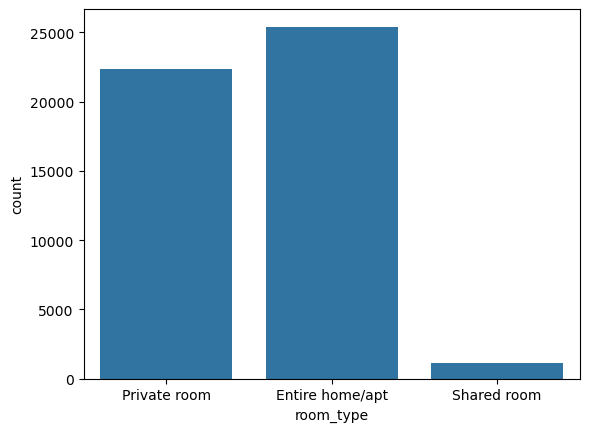

In [10]:
sns.countplot(x=df['room_type'])

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

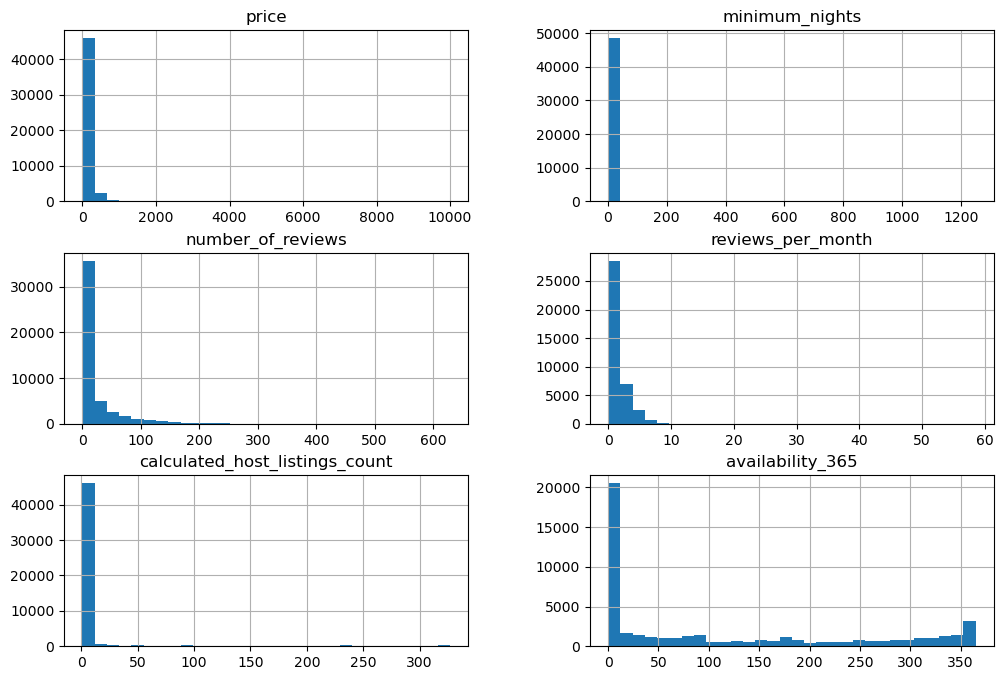

In [11]:
numerical_cols = ["price", "minimum_nights", "number_of_reviews",
                 "reviews_per_month", "calculated_host_listings_count",
                 "availability_365"]

df[numerical_cols].hist(bins=30, figsize=(12, 8))

<Axes: xlabel='neighbourhood_group', ylabel='count'>

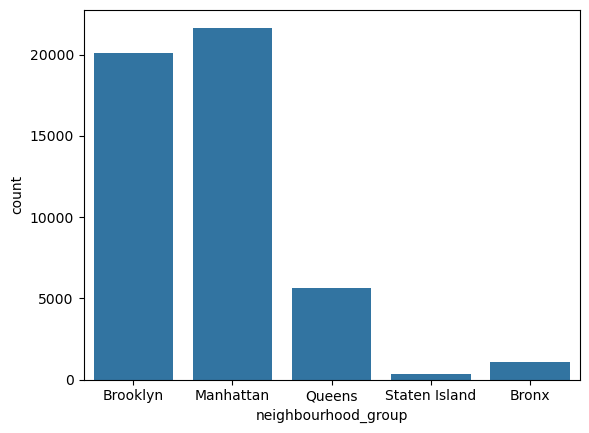

In [12]:
sns.countplot(x=df['neighbourhood_group'])

<Axes: xlabel='room_type', ylabel='price'>

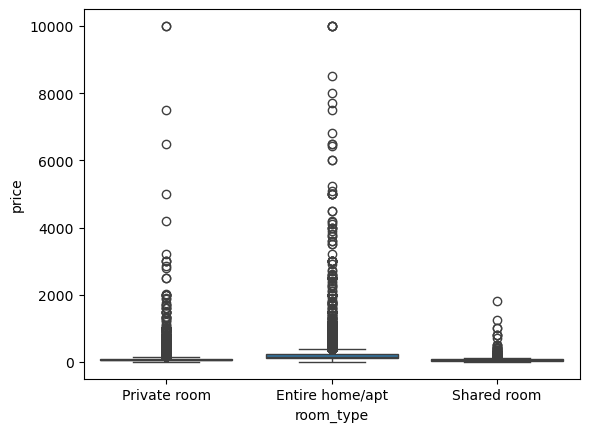

In [13]:
sns.boxplot(x=df['room_type'],y=df['price'])

<Axes: >

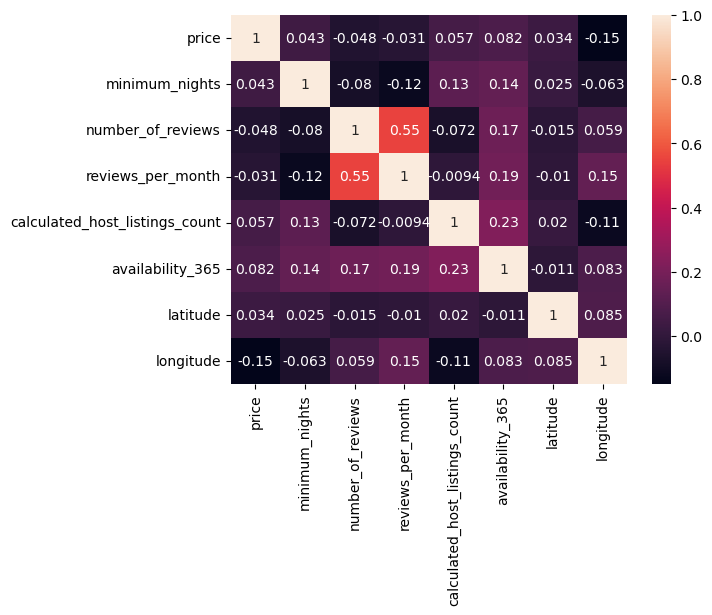

In [14]:
numerical_cols = ["price", "minimum_nights", "number_of_reviews",
                 "reviews_per_month", "calculated_host_listings_count",
                 "availability_365",'latitude','longitude']
df[numerical_cols].corr()
sns.heatmap(df[numerical_cols].corr(),annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

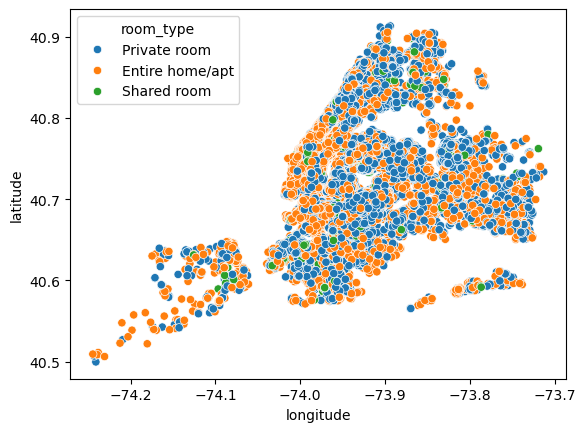

In [15]:
sns.scatterplot(x=df['longitude'],y=df['latitude'],hue=df['room_type'])

In [16]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [17]:
df_cleaned=df.drop(['id', 'name', 'host_id', 'host_name', 'last_review'],axis=1)

In [18]:
df_cleaned.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [19]:
df_cleaned.fillna(0,inplace=True)

In [20]:
price_cap  = df_cleaned['price'].quantile(0.99)
nights_cap = df_cleaned['minimum_nights'].quantile(0.99)

df_cleaned['price'] = df_cleaned['price'].clip(upper=price_cap)
df_cleaned['minimum_nights'] = df_cleaned['minimum_nights'].clip(upper=nights_cap)

In [21]:
x=df_cleaned.drop('room_type',axis=1)
y=df_cleaned['room_type']

## trying

In [22]:
x.head()

,neighbourhood_group,neighbourhood,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,150,3,0,0.00,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,80,10,9,0.10,1,0


In [23]:
from sklearn.model_selection import train_test_split


In [24]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42,stratify=y)

In [25]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [26]:
len(x['calculated_host_listings_count'].unique())

47

In [27]:
cat_cols = ['neighbourhood_group', 'neighbourhood']

ohe = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

x_train_cat = ohe.fit_transform(x_train[cat_cols])
x_test_cat = ohe.transform(x_test[cat_cols])


In [28]:

scaler = StandardScaler()

In [29]:
col=['latitude','longitude','price','minimum_nights','number_of_reviews','reviews_per_month','availability_365']

In [30]:
x_train_num=scaler.fit_transform(x_train[col])
x_test_num=scaler.transform(x_test[col])


In [31]:
x_train_final = np.hstack([
    x_train_num,
    x_train_cat
])

x_test_final = np.hstack([
    x_test_num,
    x_test_cat
])

In [33]:
from sklearn.metrics import accuracy_score

In [34]:
from sklearn.ensemble import RandomForestClassifier
model1=RandomForestClassifier()

In [35]:
model1.fit(x_train_final,y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
model1.predict(x_test_final)

array(['Private room', 'Private room', 'Entire home/apt', ...,
       'Entire home/apt', 'Entire home/apt', 'Private room'],
      shape=(9779,), dtype=object)

In [37]:
y_test

15603       Private room
5781        Private room
40927    Entire home/apt
42211       Private room
44056    Entire home/apt
              ...       
13589    Entire home/apt
32082       Private room
9387     Entire home/apt
47922    Entire home/apt
20218       Private room
Name: room_type, Length: 9779, dtype: object

In [38]:
accuracy_score(y_test,model1.predict(x_test_final))

0.8544840985785868

In [39]:
from sklearn.metrics import classification_report,f1_score,precision_score,recall_score,confusion_matrix, ConfusionMatrixDisplay


In [40]:
print(classification_report(y_test,model1.predict(x_test_final)))

                 precision    recall  f1-score   support

Entire home/apt       0.87      0.89      0.88      5082
   Private room       0.84      0.85      0.84      4465
    Shared room       0.88      0.26      0.41       232

       accuracy                           0.85      9779
      macro avg       0.86      0.67      0.71      9779
   weighted avg       0.85      0.85      0.85      9779



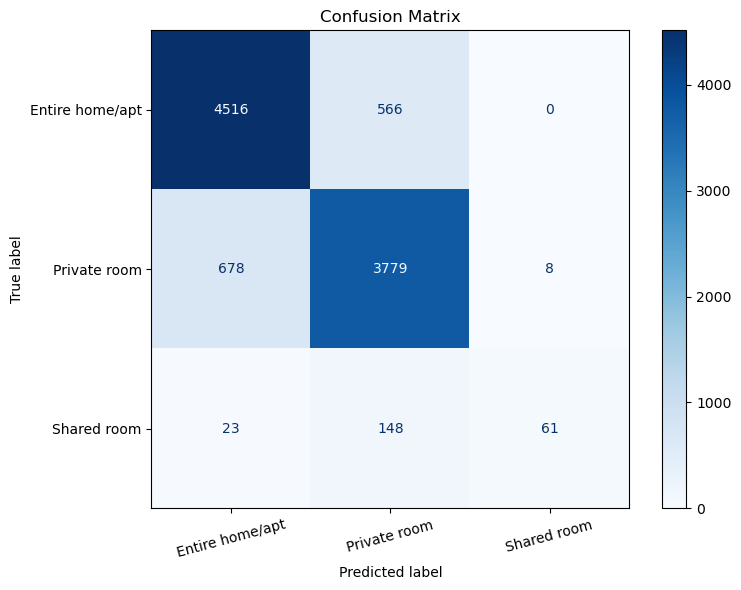

In [41]:
cm = confusion_matrix(
    y_test,
    model1.predict(x_test_final),
    labels=model1.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model1.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [44]:
import joblib

joblib.dump(model1, "Model_1.pkl",compress=3)

['Model_1.pkl']

In [45]:
joblib.dump(scaler, "scaler.pkl",compress=3)

['scaler.pkl']

In [46]:
joblib.dump(x.columns.tolist(),'columns.pkl')

['columns.pkl']

In [48]:
joblib.dump(ohe, "ohe.pkl")

['ohe.pkl']

In [50]:
import json
meta = {
    "neighbourhoods": df.groupby("neighbourhood_group")["neighbourhood"]
                        .unique().apply(lambda s: sorted(s)).to_dict(),
    "price_cap": float(price_cap),
    "nights_cap": float(nights_cap),
    "sample": df_cleaned.sample(3000, random_state=1)
                [["latitude", "longitude", "price", "room_type"]]
                .round(5).to_dict("records"),
}
json.dump(meta, open("meta.json", "w"))